# MSCS 634 — Lab 1
## Factors Associated with Five-Year Home Price Growth in California

**Name:** Sammy Sheu
**Course:** MSCS 634 — Big Data and Data Mining
**Assignment:** Lab 1 — Data Visualization, Preprocessing, and Statistical Analysis

---

### Objective

Explore, clean, and statistically analyze a dataset of **California ZIP codes observed in 2020**,
where the goal is to understand what was associated with **home-price growth over the following
five years (2020 → 2025)**.

Each row is one California ZIP code. The target, `future_5yr_growth_pct`, is the percentage change
in home value from December 2020 to December 2025 — a *completed* five-year window, so the outcome
is observed rather than assumed.

### Data sources

| Source | Contributes |
|---|---|
| **Zillow ZHVI** (ZIP, smoothed, seasonally adjusted) | Home values: 2020 level, prior-year growth, and the 2025 outcome |
| **Zillow ZORI** (ZIP) | Observed asking rent — sparse; used here to demonstrate missing-value handling |
| **US Census ACS 5-Year** (ZCTA) | Median household income, median gross rent, population, unemployment, education |
| **FRED `MORTGAGE30US`** | National 30-year fixed mortgage rate (annual mean) |

---
## Step 1 — Data Collection

The dataset was assembled by `scripts/build_dataset.py`, which joins the four sources above on ZIP
code. ZIP codes are loaded **as strings** to preserve leading zeros.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

# zip_code MUST be read as a string, or leading zeros are silently destroyed.
df_raw = pd.read_csv(
    "../data/processed/ca_zip_housing_2020_snapshot.csv",
    dtype={"zip_code": str},
)

print(f"Rows (California ZIP codes): {df_raw.shape[0]}")
print(f"Columns:                     {df_raw.shape[1]}")

Rows (California ZIP codes): 1528
Columns:                     28


### 📸 **SCREENSHOT 1** — first five rows of the dataset

In [2]:
df_raw.head()

,zip_code,base_year,city,county,current_home_value,future_5yr_home_value,home_value_1yr_growth_pct,home_value_3yr_growth_pct,future_5yr_growth_pct,zori_rent,zori_rent_available,median_household_income,median_gross_rent,population,housing_units,unemployment_rate,bachelor_degree_pct,population_growth_pct,mortgage_rate,price_to_income_ratio,price_to_rent_ratio,for_sale_inventory,new_listings,price_cut_pct,median_list_price,inventory_per_1k_housing_units,new_listings_per_1k_housing_units,list_to_value_ratio
0,90011,2020,Los Angeles,Los Angeles County,501208.842694,612812.166309,10.364995,44.768978,22.266831,NaN,0,44616.0,1228.0,110750.0,25754.0,9.033768,6.860649,6.431029,3.111698,11.233836,34.012544,30.0,NaN,NaN,NaN,1.164868,NaN,NaN
1,90650,2020,Norwalk,Los Angeles County,580635.867418,763103.536640,10.531390,28.113757,31.425490,2128.645916,1,77425.0,1678.0,104524.0,27701.0,5.546215,20.256719,-2.001706,3.111698,7.499333,28.835711,74.0,41.0,0.061740,548166.0,2.671384,1.480091,0.944079
2,91331,2020,Los Angeles,Los Angeles County,565025.787777,746856.266049,11.638229,38.588440,32.180917,NaN,0,64375.0,1400.0,103683.0,24116.0,5.911705,10.435226,1.385602,3.111698,8.777100,33.632487,62.0,29.0,0.087866,578133.0,2.570907,1.202521,1.023198
3,90044,2020,Los Angeles,Los Angeles County,545801.991182,657790.207861,10.279367,43.670969,20.518103,1947.656652,1,39434.0,1163.0,99980.0,29584.0,8.538142,8.604351,12.368643,3.111698,13.840898,39.108770,61.0,NaN,0.131269,563500.0,2.061925,NaN,1.032426
4,92336,2020,Fontana,San Bernardino County,508502.505419,703565.066478,9.118856,18.871782,38.360197,NaN,0,96447.0,1765.0,98731.0,26206.0,4.177657,25.747022,6.412951,3.111698,5.272352,24.008617,144.0,76.0,0.060537,539733.0,5.494925,2.900099,1.061417


Each row is one California ZIP code with a **base year of 2020**.

- **Predictors** describe the ZIP as it stood in 2020: home value, one- and three-year price
  momentum, income, rent, population growth, unemployment, education, the mortgage rate, and two
  affordability ratios.
- **Target:** `future_5yr_growth_pct` — realized home-price growth from Dec 2020 to Dec 2025.

Because 2020 → 2025 has fully elapsed, the outcome is **measured, not forecast**.

---
## Step 2 — Data Visualization

Four visualizations, each followed by its interpretation.

#### Visualization 1 — Household income vs. home value (scatter)

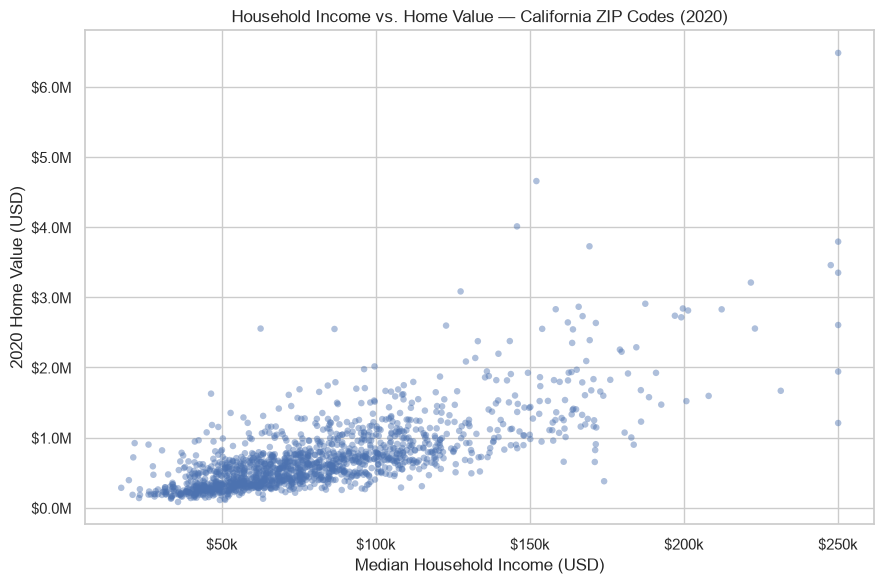

Pearson correlation: r = 0.738


In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df_raw["median_household_income"], df_raw["current_home_value"],
           alpha=0.45, s=22, edgecolor="none")
ax.set_xlabel("Median Household Income (USD)")
ax.set_ylabel("2020 Home Value (USD)")
ax.set_title("Household Income vs. Home Value — California ZIP Codes (2020)")
ax.xaxis.set_major_formatter(lambda x, _: f"${x/1000:.0f}k")
ax.yaxis.set_major_formatter(lambda x, _: f"${x/1e6:.1f}M")
plt.tight_layout()
plt.show()

r = df_raw["median_household_income"].corr(df_raw["current_home_value"])
print(f"Pearson correlation: r = {r:.3f}")

**Insight — a strong positive relationship (r = 0.738).** Higher-income ZIP codes command higher
home values, which is unsurprising but confirms the data behaves sensibly.

Two details matter more than the headline correlation. First, the spread **fans out** as income
rises: below roughly \$75k income, home values cluster tightly, but above \$150k they range from
under \$1M to over \$6M. Income sets a floor on home value far more reliably than it sets a
ceiling — something else (coastal location, school reputation, land scarcity) drives the top end.

Second, the relationship is strong enough to create **collinearity**, since income, rent, and home
value all move together. This is precisely why the Project uses Ridge regression rather than
ordinary least squares: with correlated predictors, OLS coefficients become unstable and their
individual magnitudes stop being trustworthy.

#### Visualization 2 — Affordability vs. future growth (scatter)

This tests the project's central hypothesis: do **already-expensive** markets subsequently grow **more slowly**?

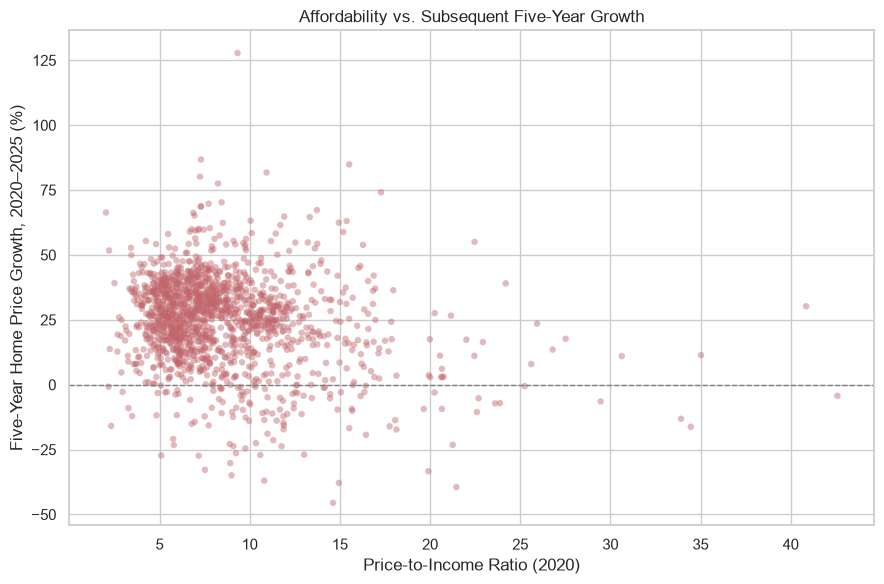

Pearson correlation: r = -0.214


In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df_raw["price_to_income_ratio"], df_raw["future_5yr_growth_pct"],
           alpha=0.45, s=22, color="#c1666b", edgecolor="none")
ax.set_xlabel("Price-to-Income Ratio (2020)")
ax.set_ylabel("Five-Year Home Price Growth, 2020–2025 (%)")
ax.set_title("Affordability vs. Subsequent Five-Year Growth")
ax.axhline(0, color="grey", lw=1, ls="--")
plt.tight_layout()
plt.show()

r = df_raw["price_to_income_ratio"].corr(df_raw["future_5yr_growth_pct"])
print(f"Pearson correlation: r = {r:.3f}")

**Insight — the affordability-constraint hypothesis is supported in *direction*, but it is weak
(r = −0.214).** ZIP codes that were already expensive relative to local income in 2020 did tend to
grow more slowly over the next five years, which is what affordability pressure would predict. But
an r of −0.21 explains under 5% of the variance, so affordability is at best a **secondary**
factor — nowhere near a complete account of where prices went.

(In Step 4 this same correlation reads **−0.173**, because the statistics there are computed on
`reduced_df`, *after* outlier removal. Removing the 43 extreme-growth ZIP codes slightly weakens the
relationship — a small but honest illustration that preprocessing choices move the numbers.)

Note the phrasing carefully: price-to-income is *negatively associated* with subsequent growth. This
is observational data, so it does **not** show that being expensive *causes* slower growth. Both
could easily be driven by a third factor, such as how much developable land remains.

### 📸 **SCREENSHOT 2** — visualizations 3 and 4 (distribution + outliers)

#### Visualization 3 — Distribution of five-year growth (histogram)

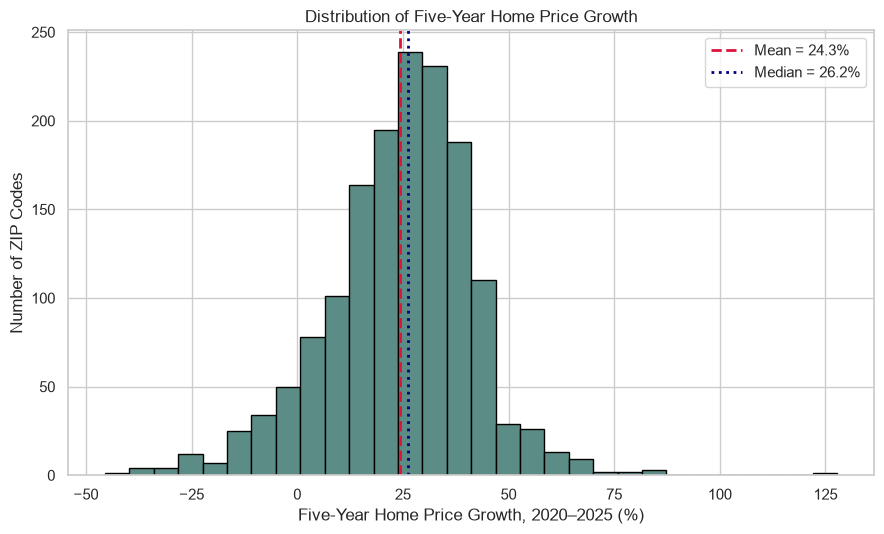

Skewness: -0.289


In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hist(df_raw["future_5yr_growth_pct"].dropna(), bins=30,
        edgecolor="black", color="#5b8c85")
ax.axvline(df_raw["future_5yr_growth_pct"].mean(), color="crimson", ls="--", lw=2,
           label=f'Mean = {df_raw["future_5yr_growth_pct"].mean():.1f}%')
ax.axvline(df_raw["future_5yr_growth_pct"].median(), color="navy", ls=":", lw=2,
           label=f'Median = {df_raw["future_5yr_growth_pct"].median():.1f}%')
ax.set_xlabel("Five-Year Home Price Growth, 2020–2025 (%)")
ax.set_ylabel("Number of ZIP Codes")
ax.set_title("Distribution of Five-Year Home Price Growth")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Skewness: {df_raw['future_5yr_growth_pct'].skew():.3f}")

**Insight — the typical California ZIP code gained about a quarter of its value in five years, but
the spread is enormous.** Mean growth is **24.3%** and median **26.2%**, with a standard deviation
of **17.3** points and a range running from **−45.5%** to **+127.8%**. Some ZIP codes nearly halved
while others more than doubled, over the *same* five years and within the *same* state.

The distribution is **mildly left-skewed (−0.29)**, so mean < median: a long thin tail of sharply
*declining* ZIP codes pulls the average below the typical value. This is the opposite of the pattern
in home *values* (which are strongly right-skewed) and is worth noticing — the losers are further
from the middle than the winners.

That long left tail is exactly what the IQR analysis in Step 3.2 will pick up.

#### Visualization 4 — Home value spread and outliers (box plot)

/var/folders/16/6_m0ygc13554c1ck_wb41mhm0000gn/T/ipykernel_98610/2786677962.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(df_raw["current_home_value"].dropna(), vert=True, widths=0.5)
/var/folders/16/6_m0ygc13554c1ck_wb41mhm0000gn/T/ipykernel_98610/2786677962.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df_raw["future_5yr_growth_pct"].dropna(), vert=True, widths=0.5)


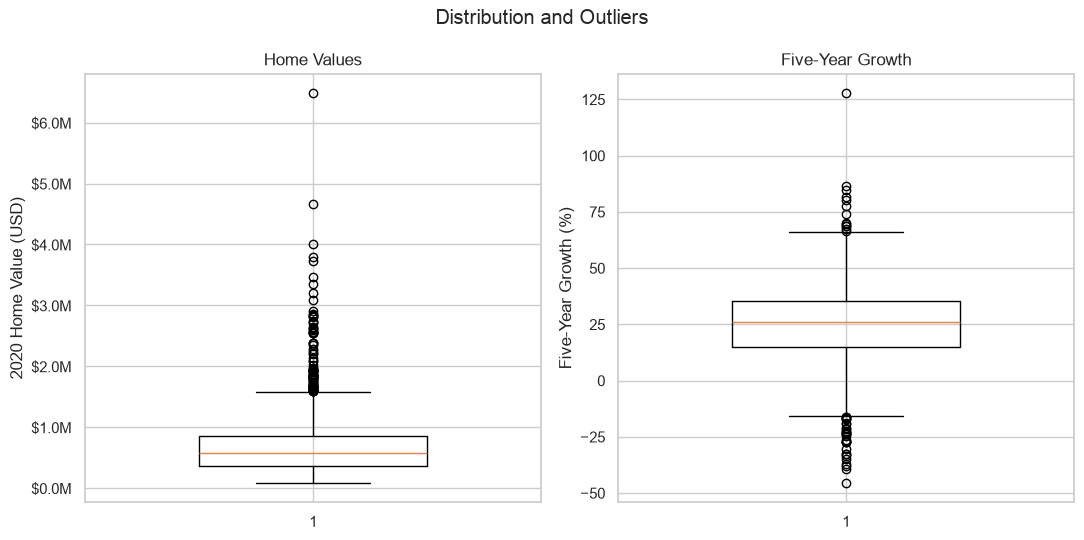

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

axes[0].boxplot(df_raw["current_home_value"].dropna(), vert=True, widths=0.5)
axes[0].set_ylabel("2020 Home Value (USD)")
axes[0].set_title("Home Values")
axes[0].yaxis.set_major_formatter(lambda x, _: f"${x/1e6:.1f}M")

axes[1].boxplot(df_raw["future_5yr_growth_pct"].dropna(), vert=True, widths=0.5)
axes[1].set_ylabel("Five-Year Growth (%)")
axes[1].set_title("Five-Year Growth")

fig.suptitle("Distribution and Outliers")
plt.tight_layout()
plt.show()

**Insight — the two panels are skewed in opposite directions.**

**Home values** are severely **right**-skewed (skew = 3.01): the mean is \$705k against a median of
\$580k, and the maximum reaches \$6.48M. A small number of ultra-expensive ZIP codes stretches the
upper tail, which is why the *median* — not the mean — was used for imputation in Step 3.1.

**Growth**, by contrast, is mildly **left**-skewed, with its outliers concentrated at the bottom.

**Important interpretive point:** high-value ZIP codes are flagged as statistical outliers, but they
are **legitimate coastal and metropolitan markets — not data-entry errors**. Atherton really does
cost what it costs. Deleting them would discard real signal, which is why outliers here are examined
and flagged rather than removed outright.

#### Visualization 5 — Mean five-year growth by county (bar chart)

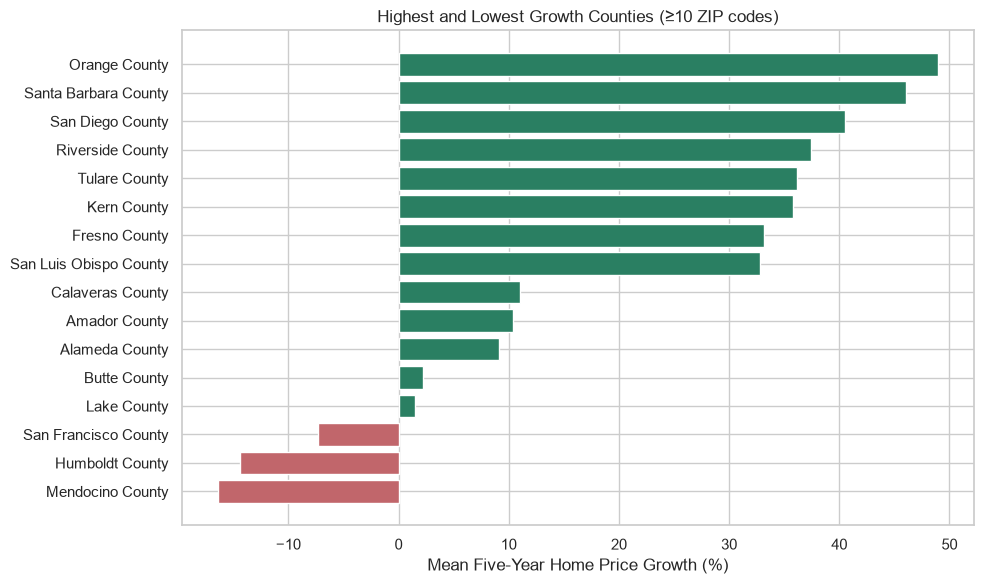

In [7]:
county = (df_raw.groupby("county")["future_5yr_growth_pct"]
          .agg(["mean", "count"])
          .query("count >= 10")
          .sort_values("mean", ascending=False))
top = pd.concat([county.head(8), county.tail(8)])

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#2a7f62" if v > 0 else "#c1666b" for v in top["mean"]]
ax.barh(top.index, top["mean"], color=colors)
ax.set_xlabel("Mean Five-Year Home Price Growth (%)")
ax.set_title("Highest and Lowest Growth Counties (≥10 ZIP codes)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Insight — geography dominates, and the pattern tells a clear story.**

Southern California's coastal counties led decisively: **Orange (+49.0%)**, **Santa Barbara
(+46.0%)**, and **San Diego (+40.5%)**. At the other end, three counties actually **lost** value:
**Mendocino (−16.4%)**, **Humboldt (−14.4%)**, and — most strikingly — **San Francisco (−7.4%)**.

San Francisco is the headline. The most expensive, highest-income, best-educated market in the state
*declined* over 2020–2025. Any model relying on income or education alone to predict growth would
have gotten San Francisco badly wrong. The remote-work shift plausibly reduced the premium on being
near dense urban job centres, while rural North Coast counties (Humboldt, Mendocino) saw sustained
declines.

This is the single most important warning in the Lab: **the level of a market's prosperity in 2020
tells you very little about its subsequent growth.** The two are almost entirely different
questions — a point the correlation analysis in Step 4 confirms numerically.

---
## Step 3 — Data Preprocessing

### 3.1 Handling Missing Values

### 📸 **SCREENSHOT 3** — missing values BEFORE handling

In [8]:
missing_before = df_raw.isnull().sum()
missing_pct = (missing_before / len(df_raw) * 100).round(1)

summary_before = pd.DataFrame({
    "missing_count": missing_before,
    "missing_pct": missing_pct,
}).query("missing_count > 0").sort_values("missing_count", ascending=False)

print("MISSING VALUES BEFORE HANDLING")
print(f"Total rows: {len(df_raw)}\n")
summary_before

MISSING VALUES BEFORE HANDLING
Total rows: 1528



,missing_count,missing_pct
zori_rent,1098,71.9
new_listings_per_1k_housing_units,939,61.5
new_listings,939,61.5
list_to_value_ratio,872,57.1
median_list_price,872,57.1
price_cut_pct,852,55.8
inventory_per_1k_housing_units,389,25.5
for_sale_inventory,388,25.4
median_gross_rent,105,6.9
price_to_rent_ratio,105,6.9


In [9]:
# Rows containing at least one missing value
df_raw[df_raw.isnull().any(axis=1)].head(10)

,zip_code,base_year,city,county,current_home_value,future_5yr_home_value,home_value_1yr_growth_pct,home_value_3yr_growth_pct,future_5yr_growth_pct,zori_rent,zori_rent_available,median_household_income,median_gross_rent,population,housing_units,unemployment_rate,bachelor_degree_pct,population_growth_pct,mortgage_rate,price_to_income_ratio,price_to_rent_ratio,for_sale_inventory,new_listings,price_cut_pct,median_list_price,inventory_per_1k_housing_units,new_listings_per_1k_housing_units,list_to_value_ratio
0,90011,2020,Los Angeles,Los Angeles County,501208.842694,612812.166309,10.364995,44.768978,22.266831,NaN,0,44616.0,1228.0,110750.0,25754.0,9.033768,6.860649,6.431029,3.111698,11.233836,34.012544,30.0,NaN,NaN,NaN,1.164868,NaN,NaN
2,91331,2020,Los Angeles,Los Angeles County,565025.787777,746856.266049,11.638229,38.588440,32.180917,NaN,0,64375.0,1400.0,103683.0,24116.0,5.911705,10.435226,1.385602,3.111698,8.777100,33.632487,62.0,29.0,0.087866,578133.0,2.570907,1.202521,1.023198
3,90044,2020,Los Angeles,Los Angeles County,545801.991182,657790.207861,10.279367,43.670969,20.518103,1947.656652,1,39434.0,1163.0,99980.0,29584.0,8.538142,8.604351,12.368643,3.111698,13.840898,39.108770,61.0,NaN,0.131269,563500.0,2.061925,NaN,1.032426
4,92336,2020,Fontana,San Bernardino County,508502.505419,703565.066478,9.118856,18.871782,38.360197,NaN,0,96447.0,1765.0,98731.0,26206.0,4.177657,25.747022,6.412951,3.111698,5.272352,24.008617,144.0,76.0,0.060537,539733.0,5.494925,2.900099,1.061417
6,92335,2020,Fontana,San Bernardino County,408439.047032,564948.119171,9.583182,21.818540,38.318832,NaN,0,58070.0,1268.0,99242.0,26017.0,7.911733,9.593048,0.812661,3.111698,7.033564,26.842734,83.0,38.0,0.054290,416318.0,3.190222,1.460583,1.019290
7,90201,2020,Bell,Los Angeles County,526932.260900,687711.122796,10.604930,35.105877,30.512245,NaN,0,46109.0,1287.0,100512.0,24866.0,7.173540,7.125974,-2.364346,3.111698,11.427970,34.118898,16.0,NaN,NaN,NaN,0.643449,NaN,NaN
8,90250,2020,Hawthorne,Los Angeles County,762680.749512,888043.407401,9.661164,36.659926,16.437108,1675.104111,1,60162.0,1340.0,95115.0,32306.0,6.536973,24.214655,-0.858879,3.111698,12.677118,47.430395,56.0,NaN,0.115792,780833.0,1.733424,NaN,1.023801
10,93307,2020,Bakersfield,Kern County,213751.077928,318590.271135,11.339540,29.571352,49.047328,NaN,0,42128.0,962.0,86273.0,24006.0,10.450707,6.324050,0.367626,3.111698,5.073848,18.516206,86.0,41.0,0.121298,216750.0,3.582438,1.707906,1.014030
11,90280,2020,South Gate,Los Angeles County,542937.662627,695936.523114,9.141383,31.812998,28.179821,NaN,0,55084.0,1211.0,94905.0,24472.0,8.833094,10.229624,-0.466702,3.111698,9.856540,37.361524,32.0,14.0,NaN,NaN,1.307617,0.572082,NaN
12,91342,2020,Los Angeles,Los Angeles County,621909.733269,807833.317965,11.259073,36.407438,29.895590,NaN,0,79572.0,1669.0,94432.0,26125.0,5.173874,17.940487,1.033531,3.111698,7.815686,31.052014,102.0,46.0,0.113014,583833.0,3.904306,1.760766,0.938775


#### Strategy — and the reasoning behind it

Filling everything with `0` would be wrong: a ZIP code with zero income does not exist, and a
zero would drag every mean and correlation toward it. Each column is treated on its merits.

| Column group | Action | Why |
|---|---|---|
| `zip_code`, `current_home_value`, `future_5yr_growth_pct` | **Drop the row** | Never impute the target or the value the target is derived from — that fabricates the answer. |
| `median_household_income`, `median_gross_rent`, `unemployment_rate`, `bachelor_degree_pct`, `population_growth_pct` | **Median imputation** | Modest missingness; the median is robust to the heavy right skew in California housing data (the mean would be pulled up by a handful of very expensive ZIPs). |
| `zori_rent` | **Leave missing; keep an availability flag** | ~72% missing, and *not missing at random* — ZORI covers large, liquid rental markets. Imputing three-quarters of a column would invent data and bias it toward big cities. ACS median gross rent serves as the rent variable instead. |

In [10]:
# 1. Drop rows where the target or its denominator is missing.
critical = ["zip_code", "current_home_value", "future_5yr_growth_pct"]
df_clean = df_raw.dropna(subset=critical).copy()
print(f"Dropped {len(df_raw) - len(df_clean)} rows missing critical fields.")

# 2. Median-impute the moderately-missing ACS features.
impute_columns = [
    "median_household_income",
    "median_gross_rent",
    "population",
    "population_growth_pct",
    "unemployment_rate",
    "bachelor_degree_pct",
    "home_value_3yr_growth_pct",
]
for column in impute_columns:
    n = df_clean[column].isna().sum()
    if n:
        median = df_clean[column].median()
        df_clean[column] = df_clean[column].fillna(median)
        print(f"  {column:<30} filled {n:>4} values with median {median:,.2f}")

# 3. Recompute the ratios so imputed inputs propagate consistently.
df_clean["price_to_income_ratio"] = (
    df_clean["current_home_value"] / df_clean["median_household_income"]
)
df_clean["price_to_rent_ratio"] = (
    df_clean["current_home_value"] / (df_clean["median_gross_rent"] * 12)
)

Dropped 0 rows missing critical fields.
  median_household_income        filled   46 values with median 74,568.00
  median_gross_rent              filled  105 values with median 1,517.00
  population                     filled    7 values with median 22,991.00
  population_growth_pct          filled    7 values with median 1.35
  unemployment_rate              filled    7 values with median 5.66
  bachelor_degree_pct            filled    7 values with median 29.82
  home_value_3yr_growth_pct      filled   29 values with median 20.37


### 📸 **SCREENSHOT 4** — missing values AFTER handling

In [11]:
missing_after = df_clean.isnull().sum()
after = pd.DataFrame({
    "missing_count": missing_after,
    "missing_pct": (missing_after / len(df_clean) * 100).round(1),
}).query("missing_count > 0").sort_values("missing_count", ascending=False)

print("MISSING VALUES AFTER HANDLING")
print(f"Rows: {len(df_raw)} -> {len(df_clean)}\n")
if after.empty:
    print("No missing values remain in any modelling column.")
else:
    print("Remaining (intentionally retained):")
    display(after)
df_clean.head()

MISSING VALUES AFTER HANDLING
Rows: 1528 -> 1528

Remaining (intentionally retained):


,missing_count,missing_pct
zori_rent,1098,71.9
new_listings,939,61.5
new_listings_per_1k_housing_units,939,61.5
median_list_price,872,57.1
list_to_value_ratio,872,57.1
price_cut_pct,852,55.8
inventory_per_1k_housing_units,389,25.5
for_sale_inventory,388,25.4
city,31,2.0
housing_units,7,0.5


,zip_code,base_year,city,county,current_home_value,future_5yr_home_value,home_value_1yr_growth_pct,home_value_3yr_growth_pct,future_5yr_growth_pct,zori_rent,zori_rent_available,median_household_income,median_gross_rent,population,housing_units,unemployment_rate,bachelor_degree_pct,population_growth_pct,mortgage_rate,price_to_income_ratio,price_to_rent_ratio,for_sale_inventory,new_listings,price_cut_pct,median_list_price,inventory_per_1k_housing_units,new_listings_per_1k_housing_units,list_to_value_ratio
0,90011,2020,Los Angeles,Los Angeles County,501208.842694,612812.166309,10.364995,44.768978,22.266831,NaN,0,44616.0,1228.0,110750.0,25754.0,9.033768,6.860649,6.431029,3.111698,11.233836,34.012544,30.0,NaN,NaN,NaN,1.164868,NaN,NaN
1,90650,2020,Norwalk,Los Angeles County,580635.867418,763103.536640,10.531390,28.113757,31.425490,2128.645916,1,77425.0,1678.0,104524.0,27701.0,5.546215,20.256719,-2.001706,3.111698,7.499333,28.835711,74.0,41.0,0.061740,548166.0,2.671384,1.480091,0.944079
2,91331,2020,Los Angeles,Los Angeles County,565025.787777,746856.266049,11.638229,38.588440,32.180917,NaN,0,64375.0,1400.0,103683.0,24116.0,5.911705,10.435226,1.385602,3.111698,8.777100,33.632487,62.0,29.0,0.087866,578133.0,2.570907,1.202521,1.023198
3,90044,2020,Los Angeles,Los Angeles County,545801.991182,657790.207861,10.279367,43.670969,20.518103,1947.656652,1,39434.0,1163.0,99980.0,29584.0,8.538142,8.604351,12.368643,3.111698,13.840898,39.108770,61.0,NaN,0.131269,563500.0,2.061925,NaN,1.032426
4,92336,2020,Fontana,San Bernardino County,508502.505419,703565.066478,9.118856,18.871782,38.360197,NaN,0,96447.0,1765.0,98731.0,26206.0,4.177657,25.747022,6.412951,3.111698,5.272352,24.008617,144.0,76.0,0.060537,539733.0,5.494925,2.900099,1.061417


### 3.2 Outlier Detection and Removal (IQR method)

Outliers are assessed on **`future_5yr_growth_pct`** (the target) rather than on home value.
Removing every expensive ZIP code would delete legitimate coastal markets and destroy real signal;
an anomalous *growth rate* is the more meaningful thing to interrogate.

### 📸 **SCREENSHOT 5** — IQR calculation and identified outliers

In [12]:
column = "future_5yr_growth_pct"

Q1 = df_clean[column].quantile(0.25)
Q3 = df_clean[column].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"IQR OUTLIER DETECTION on '{column}'")
print(f"  Q1  (25th percentile) : {Q1:8.2f}%")
print(f"  Q3  (75th percentile) : {Q3:8.2f}%")
print(f"  IQR (Q3 - Q1)         : {IQR:8.2f}%")
print(f"  Lower bound (Q1-1.5*IQR): {lower_bound:8.2f}%")
print(f"  Upper bound (Q3+1.5*IQR): {upper_bound:8.2f}%")

outliers = df_clean[
    (df_clean[column] < lower_bound) | (df_clean[column] > upper_bound)
]
print(f"\n  Outliers identified: {len(outliers)} of {len(df_clean)} "
      f"({len(outliers)/len(df_clean)*100:.1f}%)")

outliers[["zip_code", "city", "county", "current_home_value", column]] \
    .sort_values(column).head(20)

IQR OUTLIER DETECTION on 'future_5yr_growth_pct'
  Q1  (25th percentile) :    14.86%
  Q3  (75th percentile) :    35.39%
  IQR (Q3 - Q1)         :    20.54%
  Lower bound (Q1-1.5*IQR):   -15.95%
  Upper bound (Q3+1.5*IQR):    66.20%

  Outliers identified: 43 of 1528 (2.8%)


,zip_code,city,county,current_home_value,future_5yr_growth_pct
1423,95526,Bridgeville,Humboldt County,475126.949308,-45.487920
1182,95542,Redway,Humboldt County,590941.409276,-39.444939
1239,95454,Laytonville,Mendocino County,537154.834813,-37.818245
1200,95428,Covelo,Mendocino County,444163.425660,-36.976800
1314,95528,Carlotta,Humboldt County,585435.325633,-34.937206
1395,95552,NaN,Trinity County,393176.681226,-33.336341
1276,95560,Redway,Humboldt County,477195.569872,-32.785839
1512,95553,Myers Flat,Humboldt County,563110.750272,-32.658020
1249,96041,Hayfork,Trinity County,260427.206176,-30.207674
1302,96048,Weaverville,Trinity County,379464.294974,-27.354568


In [13]:
df_no_outliers = df_clean[
    df_clean[column].between(lower_bound, upper_bound)
].copy()

print(f"Before outlier removal: {df_clean.shape}")
print(f"After outlier removal:  {df_no_outliers.shape}")
print(f"Rows removed:           {len(df_clean) - len(df_no_outliers)}")

Before outlier removal: (1528, 28)
After outlier removal:  (1485, 28)
Rows removed:           43


**What the outliers actually are — and why this matters.**

The IQR rule flags **43 ZIP codes (2.8%)**, split **30 below** the lower bound and **13 above** the
upper. Inspecting them shows they are not noise at all; they are two coherent economic stories:

- **The low outliers are rural North Coast markets** — Bridgeville, Redway (Humboldt), Laytonville,
  Covelo (Mendocino) — which lost **35–45%** of their value. These are real, sustained regional
  declines, not bad records.
- **The high outliers are affluent Southern California coastal markets** — Carlsbad (+127.8%), and
  several Irvine and Newport Beach ZIP codes (+80–87%).

Every one of these is a **legitimate market**, not a data-entry error. Discarding them would delete
precisely the observations the Project most needs to explain — the extremes are the phenomenon, not
a defect in measuring it.

> **Design decision.** Three DataFrames are kept side by side — `df_raw`, `df_clean`, and
> `df_no_outliers` — and the original is never overwritten. `df_no_outliers` exists to satisfy the
> Lab's requirement to *demonstrate* outlier removal, but the Project (Deliverable 1 onward) will
> **flag** outliers rather than delete them, for the reason above. Destroying the original in place
> is an irreversible and common mistake.

### 3.3 Data Reduction

### 📸 **SCREENSHOT 6** — data reduction (sampling + dimension elimination)

In [14]:
# --- Sampling: 30% random sample ---
sample_df = df_no_outliers.sample(frac=0.30, random_state=42)
print("SAMPLING (30%)")
print(f"  Before: {df_no_outliers.shape[0]} rows")
print(f"  After:  {sample_df.shape[0]} rows\n")

# --- Dimension elimination ---
# NOTE: `population` is deliberately RETAINED. An earlier draft dropped it as a "size proxy",
# but the correlation analysis in Step 4 shows it is the second-strongest correlate with the
# target (r = +0.277). Dropping it would discard real signal -- a reminder that dimension
# elimination must be justified by evidence, not by intuition about what "ought" to matter.
drop_columns = [
    "future_5yr_home_value",   # the target restated -> direct leakage if modelled
    "zori_rent",               # ~72% missing and not missing at random
    "zori_rent_available",     # only meaningful alongside zori_rent
    "housing_units",           # only needed to normalise the listings features (unused in Lab 1)
]
reduced_df = df_no_outliers.drop(columns=drop_columns, errors="ignore")

print("DIMENSION ELIMINATION")
print(f"  Before: {df_no_outliers.shape[1]} columns")
print(f"  After:  {reduced_df.shape[1]} columns")
print(f"  Dropped: {drop_columns}")

SAMPLING (30%)
  Before: 1485 rows
  After:  446 rows

DIMENSION ELIMINATION
  Before: 28 columns
  After:  24 columns
  Dropped: ['future_5yr_home_value', 'zori_rent', 'zori_rent_available', 'housing_units']


**Why each column was dropped**

- `future_5yr_home_value` — the target expressed in dollars. Keeping it beside
  `future_5yr_growth_pct` would let any model read the answer directly.
- `zori_rent` / `zori_rent_available` — 72% missing and biased toward large rental markets; ACS
  median gross rent covers the same concept with near-complete coverage.
- `housing_units` — only exists to normalise the for-sale-listings features, which Lab 1 does not use.

**Why `population` was *kept*.** An earlier version of this analysis dropped it, reasoning that raw
population is a "size proxy, not a growth signal." **The correlation analysis in Step 4 refutes
that**: `population` is the *second-strongest* correlate with five-year growth in the entire dataset
(**r = +0.277**), behind only price momentum. Larger, more urban ZIP codes genuinely did appreciate
faster over 2020–2025.

This is worth dwelling on, because it is the real lesson of dimension elimination: **columns must be
dropped on evidence, not on intuition about what "ought" to matter.** Removing `population` would
have quietly discarded one of the dataset's strongest available signals — and the justification
would have been contradicted by the notebook's own correlation table a few cells later.

Sampling here is a **demonstration only**. The Project's models will use the full dataset — throwing
away 70% of a 1,500-row dataset would needlessly weaken them.

### 3.4 Data Scaling and Discretization

### 📸 **SCREENSHOT 7** — before and after scaling / discretization

In [15]:
from sklearn.preprocessing import MinMaxScaler

scale_columns = [
    "current_home_value",
    "median_gross_rent",
    "median_household_income",
    "unemployment_rate",
    "bachelor_degree_pct",
    "price_to_income_ratio",
    "future_5yr_growth_pct",
]

print("BEFORE SCALING (original units)")
display(reduced_df[scale_columns].head())
display(reduced_df[scale_columns].describe().loc[["min", "max"]])

BEFORE SCALING (original units)


,current_home_value,median_gross_rent,median_household_income,unemployment_rate,bachelor_degree_pct,price_to_income_ratio,future_5yr_growth_pct
0,501208.842694,1228.0,44616.0,9.033768,6.860649,11.233836,22.266831
1,580635.867418,1678.0,77425.0,5.546215,20.256719,7.499333,31.425490
2,565025.787777,1400.0,64375.0,5.911705,10.435226,8.777100,32.180917
3,545801.991182,1163.0,39434.0,8.538142,8.604351,13.840898,20.518103
4,508502.505419,1765.0,96447.0,4.177657,25.747022,5.272352,38.360197


,current_home_value,median_gross_rent,median_household_income,unemployment_rate,bachelor_degree_pct,price_to_income_ratio,future_5yr_growth_pct
min,8.281799e+04,475.0,17270.0,0.000000,0.000000,2.028227,-15.872431
max,6.483301e+06,3501.0,250001.0,48.529412,93.989167,42.589966,66.195444


In [16]:
scaled_df = reduced_df.copy()
scaler = MinMaxScaler()
scaled_df[scale_columns] = scaler.fit_transform(scaled_df[scale_columns])

print("AFTER MIN-MAX SCALING (every column now on [0, 1])")
display(scaled_df[scale_columns].head())
display(scaled_df[scale_columns].describe().loc[["min", "max"]])

AFTER MIN-MAX SCALING (every column now on [0, 1])


,current_home_value,median_gross_rent,median_household_income,unemployment_rate,bachelor_degree_pct,price_to_income_ratio,future_5yr_growth_pct
0,0.065369,0.248843,0.117500,0.186150,0.072994,0.226953,0.464728
1,0.077778,0.397555,0.258474,0.114286,0.215522,0.134883,0.576327
2,0.075339,0.305684,0.202401,0.121817,0.111026,0.166385,0.585532
3,0.072336,0.227363,0.095234,0.175937,0.091546,0.291227,0.443420
4,0.066508,0.426305,0.340208,0.086085,0.273936,0.079980,0.660827


,current_home_value,median_gross_rent,median_household_income,unemployment_rate,bachelor_degree_pct,price_to_income_ratio,future_5yr_growth_pct
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Min-Max scaling maps each feature onto `[0, 1]`. Without it, `current_home_value` (~10⁶) would
utterly dominate `unemployment_rate` (~10⁰) in any distance-based algorithm — which is exactly why
the Project's K-Means clustering (Deliverable 3) depends on this step.

#### Discretization — continuous growth into ordered categories

In [17]:
# Terciles: equal-sized Low / Medium / High growth groups.
# Computed on the UNSCALED values so the boundaries stay interpretable as percentages.
scaled_df["growth_category"] = pd.qcut(
    reduced_df["future_5yr_growth_pct"],
    q=3,
    labels=["Low Growth", "Medium Growth", "High Growth"],
)

bounds = pd.qcut(reduced_df["future_5yr_growth_pct"], q=3).cat.categories
print("Tercile boundaries (percentage growth):")
for label, interval in zip(["Low", "Medium", "High"], bounds):
    print(f"  {label:<8} {interval}")

print("\nZIP codes per category:")
print(scaled_df["growth_category"].value_counts().sort_index().to_string())

scaled_df[["zip_code", "city", "growth_category"]] \
    .assign(future_5yr_growth_pct=reduced_df["future_5yr_growth_pct"].round(1)) \
    .head(15)

Tercile boundaries (percentage growth):
  Low      (-15.873, 19.523]
  Medium   (19.523, 32.212]
  High     (32.212, 66.195]

ZIP codes per category:
growth_category
Low Growth       495
Medium Growth    495
High Growth      495


,zip_code,city,growth_category,future_5yr_growth_pct
0,90011,Los Angeles,Medium Growth,22.3
1,90650,Norwalk,Medium Growth,31.4
2,91331,Los Angeles,Medium Growth,32.2
3,90044,Los Angeles,Medium Growth,20.5
4,92336,Fontana,High Growth,38.4
5,94565,Pittsburg,Low Growth,12.3
6,92335,Fontana,High Growth,38.3
7,90201,Bell,Medium Growth,30.5
8,90250,Hawthorne,Low Growth,16.4
9,90805,Long Beach,Medium Growth,27.8


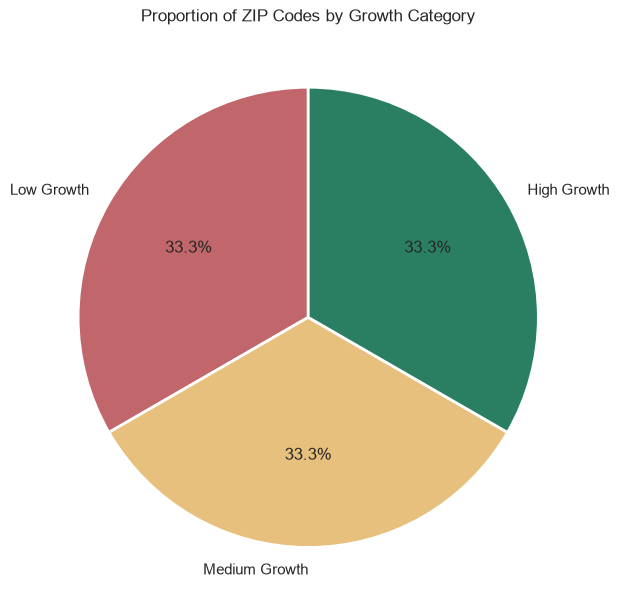

In [18]:
# Pie chart of the discretized categories
counts = scaled_df["growth_category"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=["#c1666b", "#e8c07d", "#2a7f62"],
       wedgeprops={"edgecolor": "white", "linewidth": 2})
ax.set_title("Proportion of ZIP Codes by Growth Category")
plt.tight_layout()
plt.show()

`growth_category` is **not** a throwaway Lab exercise. It is reused directly in the Project:
as the label for **classification** and as an item for **association rule mining** (Deliverable 3).

---
## Step 4 — Statistical Analysis

### 📸 **SCREENSHOT 8** — `.info()` and `.describe()`

In [19]:
reduced_df.info()

<class 'pandas.DataFrame'>
Index: 1485 entries, 0 to 1527
Data columns (total 24 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   zip_code                           1485 non-null   str    
 1   base_year                          1485 non-null   int64  
 2   city                               1456 non-null   str    
 3   county                             1485 non-null   str    
 4   current_home_value                 1485 non-null   float64
 5   home_value_1yr_growth_pct          1485 non-null   float64
 6   home_value_3yr_growth_pct          1485 non-null   float64
 7   future_5yr_growth_pct              1485 non-null   float64
 8   median_household_income            1485 non-null   float64
 9   median_gross_rent                  1485 non-null   float64
 10  population                         1485 non-null   float64
 11  unemployment_rate                  1485 non-null   float64
 12  bachelor

In [20]:
reduced_df.describe().T

,count,mean,std,min,25%,50%,75%,max
base_year,1485.0,2020.000000,0.000000e+00,2020.000000,2020.000000,2020.000000,2020.000000,2.020000e+03
current_home_value,1485.0,702723.278406,5.226317e+05,82817.992039,359748.205127,577199.063163,846302.897103,6.483301e+06
home_value_1yr_growth_pct,1485.0,8.986917,3.265705e+00,-5.067210,7.496494,9.416309,10.603983,2.969022e+01
home_value_3yr_growth_pct,1485.0,21.870943,9.538459e+00,-11.919761,15.423496,20.400978,27.253770,7.535329e+01
future_5yr_growth_pct,1485.0,24.855490,1.502763e+01,-15.872431,15.616457,26.406115,35.232204,6.619544e+01
median_household_income,1485.0,81909.406061,3.594014e+04,17270.000000,56313.000000,74568.000000,98879.000000,2.500010e+05
median_gross_rent,1485.0,1578.148148,5.456201e+02,475.000000,1175.000000,1517.000000,1882.000000,3.501000e+03
population,1485.0,26007.913131,2.251134e+04,21.000000,4692.000000,23107.000000,40216.000000,1.107500e+05
unemployment_rate,1485.0,6.554018,4.580463e+00,0.000000,4.130322,5.658990,7.859966,4.852941e+01
bachelor_degree_pct,1485.0,33.487066,2.007673e+01,0.000000,17.481221,29.767946,47.171800,9.398917e+01


### 📸 **SCREENSHOT 9** — central tendency

In [21]:
numeric_df = reduced_df.select_dtypes(include="number").drop(columns=["base_year"], errors="ignore")

central_tendency = pd.DataFrame({
    "Minimum": numeric_df.min(),
    "Maximum": numeric_df.max(),
    "Mean":    numeric_df.mean(),
    "Median":  numeric_df.median(),
    "Mode":    numeric_df.mode().iloc[0],
})
central_tendency.round(2)

,Minimum,Maximum,Mean,Median,Mode
current_home_value,82817.99,6483301.32,702723.28,577199.06,82817.99
home_value_1yr_growth_pct,-5.07,29.69,8.99,9.42,-5.07
home_value_3yr_growth_pct,-11.92,75.35,21.87,20.40,20.37
future_5yr_growth_pct,-15.87,66.20,24.86,26.41,-15.87
median_household_income,17270.00,250001.00,81909.41,74568.00,74568.00
median_gross_rent,475.00,3501.00,1578.15,1517.00,1517.00
population,21.00,110750.00,26007.91,23107.00,22991.00
unemployment_rate,0.00,48.53,6.55,5.66,0.00
bachelor_degree_pct,0.00,93.99,33.49,29.77,29.82
population_growth_pct,-83.27,646.81,3.41,1.35,1.35


**Reading this table:** where **mean > median**, the feature is right-skewed — a minority of very
expensive ZIP codes pulls the average above the typical value. This is why the *median* was used for
imputation in Step 3.1.

### 📸 **SCREENSHOT 10** — dispersion

In [22]:
dispersion = pd.DataFrame({
    "Range":              numeric_df.max() - numeric_df.min(),
    "Q1":                 numeric_df.quantile(0.25),
    "Q3":                 numeric_df.quantile(0.75),
    "IQR":                numeric_df.quantile(0.75) - numeric_df.quantile(0.25),
    "Variance":           numeric_df.var(),
    "Standard_Deviation": numeric_df.std(),
})
dispersion.round(2)

,Range,Q1,Q3,IQR,Variance,Standard_Deviation
current_home_value,6400483.33,359748.21,846302.90,486554.69,2.731439e+11,522631.68
home_value_1yr_growth_pct,34.76,7.50,10.60,3.11,1.066000e+01,3.27
home_value_3yr_growth_pct,87.27,15.42,27.25,11.83,9.098000e+01,9.54
future_5yr_growth_pct,82.07,15.62,35.23,19.62,2.258300e+02,15.03
median_household_income,232731.00,56313.00,98879.00,42566.00,1.291693e+09,35940.14
median_gross_rent,3026.00,1175.00,1882.00,707.00,2.977012e+05,545.62
population,110729.00,4692.00,40216.00,35524.00,5.067606e+08,22511.34
unemployment_rate,48.53,4.13,7.86,3.73,2.098000e+01,4.58
bachelor_degree_pct,93.99,17.48,47.17,29.69,4.030700e+02,20.08
population_growth_pct,730.08,-2.52,6.40,8.92,8.671600e+02,29.45


### 📸 **SCREENSHOT 11** — correlation matrix

In [23]:
correlation_matrix = numeric_df.corr()
correlation_matrix.round(3)

,current_home_value,home_value_1yr_growth_pct,home_value_3yr_growth_pct,future_5yr_growth_pct,median_household_income,median_gross_rent,population,unemployment_rate,bachelor_degree_pct,population_growth_pct,mortgage_rate,price_to_income_ratio,price_to_rent_ratio,for_sale_inventory,new_listings,price_cut_pct,median_list_price,inventory_per_1k_housing_units,new_listings_per_1k_housing_units,list_to_value_ratio
current_home_value,1.000,-0.296,-0.180,-0.020,0.734,0.690,0.047,-0.293,0.744,-0.031,NaN,0.673,0.834,0.125,-0.091,0.278,0.956,0.068,-0.178,0.030
home_value_1yr_growth_pct,-0.296,1.000,0.536,0.312,-0.257,-0.287,0.023,0.145,-0.380,-0.030,NaN,-0.251,-0.251,-0.117,0.039,-0.274,-0.340,-0.003,0.146,0.062
home_value_3yr_growth_pct,-0.180,0.536,1.000,0.060,-0.348,-0.301,0.092,0.258,-0.382,-0.057,NaN,0.017,-0.114,-0.147,-0.238,-0.096,-0.068,-0.156,-0.228,-0.060
future_5yr_growth_pct,-0.020,0.312,0.060,1.000,0.094,0.126,0.277,-0.030,-0.042,-0.042,NaN,-0.173,-0.148,0.094,0.169,-0.163,-0.066,-0.003,0.172,0.181
median_household_income,0.734,-0.257,-0.348,0.094,1.000,0.825,0.054,-0.378,0.764,0.032,NaN,0.114,0.435,0.149,0.135,0.146,0.686,0.129,0.178,0.074
median_gross_rent,0.690,-0.287,-0.301,0.126,0.825,1.000,0.189,-0.363,0.737,0.040,NaN,0.253,0.281,0.157,0.086,0.131,0.653,0.030,0.044,-0.028
population,0.047,0.023,0.092,0.277,0.054,0.189,1.000,-0.061,-0.011,-0.023,NaN,0.071,-0.038,0.331,0.280,-0.201,-0.152,-0.473,-0.418,-0.302
unemployment_rate,-0.293,0.145,0.258,-0.030,-0.378,-0.363,-0.061,1.000,-0.361,0.074,NaN,-0.109,-0.210,-0.059,-0.073,-0.210,-0.401,-0.060,-0.064,-0.055
bachelor_degree_pct,0.744,-0.380,-0.382,-0.042,0.764,0.737,-0.011,-0.361,1.000,0.018,NaN,0.410,0.554,0.240,0.113,0.423,0.735,0.147,0.088,0.063
population_growth_pct,-0.031,-0.030,-0.057,-0.042,0.032,0.040,-0.023,0.074,0.018,1.000,NaN,-0.052,-0.052,0.074,0.193,-0.092,-0.094,-0.007,0.263,0.019


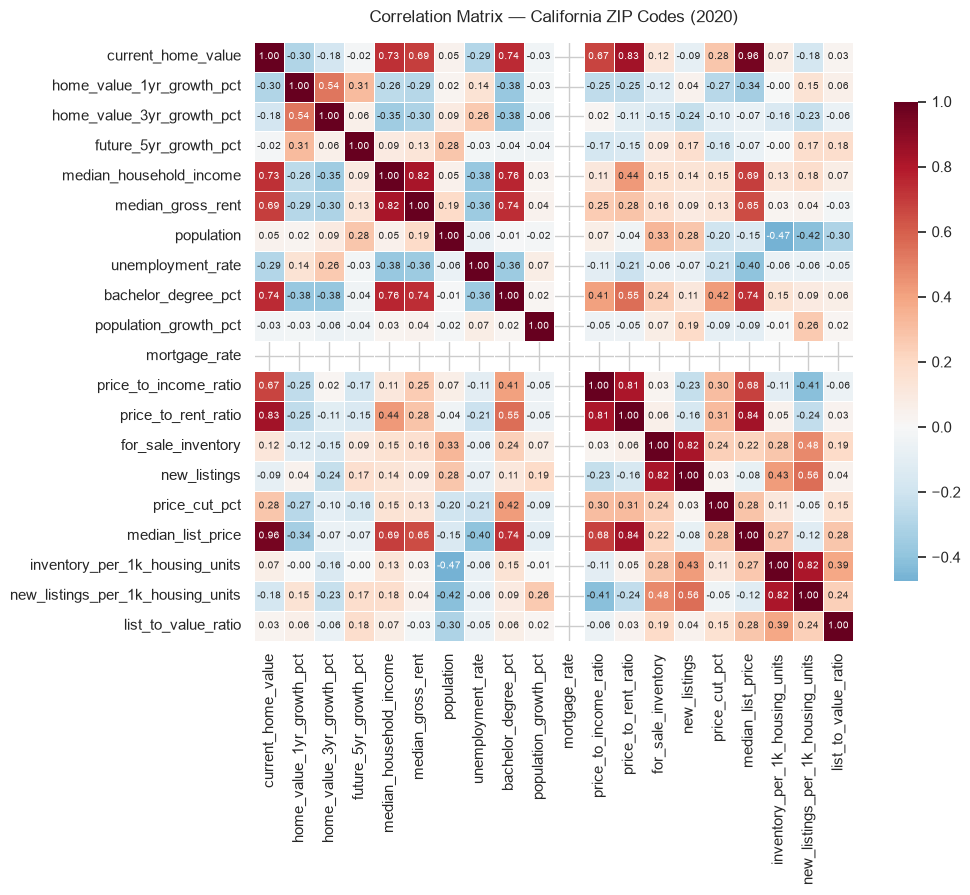

In [24]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation Matrix — California ZIP Codes (2020)", pad=14)
plt.tight_layout()
plt.show()

In [25]:
# Which features correlate most strongly with the target?
target_corr = (correlation_matrix["future_5yr_growth_pct"]
               .drop("future_5yr_growth_pct")
               .sort_values(key=abs, ascending=False))

print("Correlation with five-year growth (strongest first):\n")
for feature, r in target_corr.items():
    direction = "positive" if r > 0 else "negative"
    strength = "strong" if abs(r) >= 0.5 else "moderate" if abs(r) >= 0.3 else "weak"
    print(f"  {feature:<32} {r:+.3f}   ({strength} {direction})")

Correlation with five-year growth (strongest first):

  home_value_1yr_growth_pct        +0.312   (moderate positive)
  population                       +0.277   (weak positive)
  list_to_value_ratio              +0.181   (weak positive)
  price_to_income_ratio            -0.173   (weak negative)
  new_listings_per_1k_housing_units +0.172   (weak positive)
  new_listings                     +0.169   (weak positive)
  price_cut_pct                    -0.163   (weak negative)
  price_to_rent_ratio              -0.148   (weak negative)
  median_gross_rent                +0.126   (weak positive)
  for_sale_inventory               +0.094   (weak positive)
  median_household_income          +0.094   (weak positive)
  median_list_price                -0.066   (weak negative)
  home_value_3yr_growth_pct        +0.060   (weak positive)
  population_growth_pct            -0.042   (weak negative)
  bachelor_degree_pct              -0.042   (weak negative)
  unemployment_rate                -0.030

---
## Preliminary Findings

> **A note on which numbers appear where.** The visualizations in Step 2 are computed on `df_raw`
> (all 1,528 ZIP codes), while the statistics in Step 4 are computed on `reduced_df` (1,485 rows,
> after outlier removal). Correlations therefore differ slightly between the two — this is expected,
> and the source of each figure is stated below.

**1. How rich a market is tells you almost nothing about how fast it will grow.**
This is the Lab's most important result. Median household income predicts a ZIP code's home *value*
strongly (**r = 0.738**), yet `current_home_value` correlates with subsequent five-year *growth* at
**r = −0.020** — indistinguishable from zero. Education is no better (`bachelor_degree_pct`,
**r = −0.042**). Prosperity in 2020 and appreciation from 2020–2025 are essentially **independent**
questions. San Francisco makes the point vividly: the state's richest, best-educated market
*declined* **7.4%**.

This finding directly validates the Project's central design choice — predicting *growth* rather
than *future price*. Had we predicted price levels, `current_home_value` would have dominated the
model and produced a high R² that concealed the fact that we had learned nothing about growth.

**2. Momentum and urban scale lead — and both are still weak.**
The two strongest correlates are `home_value_1yr_growth_pct` (**r = +0.312**) and `population`
(**r = +0.277**). ZIP codes already appreciating in 2020 tended to keep appreciating, and larger,
more urban ZIP codes appreciated faster.

But r ≈ 0.31 explains only ~10% of the variance, so **no single feature in this dataset comes close
to explaining five-year growth.** That is itself a finding: Deliverable 2's regression must lean on
the *combination* of features, and expectations for predictive accuracy should be modest.

`population` also carries a methodological lesson. It was nearly discarded in Step 3.3 as a mere
"size proxy" — an intuition the data flatly contradicts. **Dimension elimination must be driven by
evidence, not by assumptions about what ought to matter.**

**3. The affordability-constraint hypothesis survives, but weakly.**
`price_to_income_ratio` is the strongest *negative* correlate (**r = −0.173** after outlier removal;
**−0.214** on the raw data): already-stretched markets grew more slowly. The direction matches the
hypothesis; the magnitude makes affordability a **secondary** factor at best, not a primary driver.

**4. Growth is a geographic story more than a demographic one.**
Southern California's coast (Orange +49.0%, Santa Barbara +46.0%, San Diego +40.5%) sharply
outperformed the rural North Coast (Mendocino −16.4%, Humboldt −14.4%). Since none of our current
features capture coastal proximity, land scarcity, or remote-work exposure, a substantial share of
the variance is being driven by factors **the dataset does not yet measure** — an honest limitation
to carry into the Project.

**5. Mortgage rate is constant in this snapshot and therefore useless here.**
Its correlation with the target is **undefined (NaN)** — the column has zero variance, because the
base year is fixed at 2020 and the rate is a *national* series. It cannot explain differences
*between* ZIP codes. It only becomes informative in the Project's multi-year panel, where it varies
*across* base years. This is a clean illustration of why a feature can be economically important yet
statistically inert given the wrong unit of analysis.

### A note on causal language

This is **observational** data. Every relationship above is an **association**, not a demonstrated
cause. The correct phrasing is *"price-to-income ratio is negatively associated with five-year
growth"* — never *"high prices cause slower growth."* No amount of correlation, and no model
accuracy score, establishes causation here.

### Challenges encountered

1. **Zillow's rent index (ZORI) proved unusable as a feature.** It covers only **431 of 1,528**
   California ZIP codes (**71.9% missing**), and the missingness is *not random* — coverage skews
   toward large, liquid rental markets. Imputing nearly three-quarters of a column would have
   fabricated data and biased it toward big cities. **Resolution:** ACS median gross rent (6.9%
   missing) became the rent variable; ZORI was retained only as this Lab's missing-value
   demonstration.

2. **The Census API rejected an unactivated key.** Requests returned an `Invalid Key` page even
   though the key was correctly formatted. **Resolution:** the key required activation via the link
   emailed by the Census Bureau before it would authenticate.

3. **ZIP codes are not ZCTAs.** Zillow uses postal ZIP codes; the Census publishes ZIP Code
   Tabulation Areas. They are similar but not identical geographies, so a small number of joins are
   approximate. **Resolution:** accepted and documented as a limitation rather than papered over.

4. **Deciding whether to delete outliers.** The IQR rule flags 43 ZIP codes, but inspection showed
   all 43 are real markets (rural North Coast declines; Orange County booms), not errors.
   **Resolution:** removal is demonstrated here to satisfy the Lab, but the Project will **flag**
   rather than delete — discarding them would remove exactly the behaviour the model needs to explain.